# NASA SMAP / MSL Anomaly Detection — Exploratory Data Analysis

**Goal:** understand the labeled anomaly metadata, check data quality, examine class/interval imbalance, and inspect real telemetry when the `.npy` files are available.

**Important:** `labeled_anomalies.csv` contains labels/metadata, not the raw telemetry values. This notebook never generates synthetic telemetry and presents it as NASA data. The telemetry plot will be skipped with a clear message if the real `.npy` files are not present.

**Interval convention:** the calculations below initially assume intervals are half-open `[start, end)` (duration = `end - start`), matching Python slicing. Confirm this convention against the dataset documentation before reporting final anomaly-point totals.


In [4]:
# Import core libraries for data processing, analysis, and visualization
import ast
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [5]:
# Configure plotting style and layout settings for clean visualizations
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['figure.autolayout'] = True

## 1. Load and inspect the label metadata

In [6]:
# Load the dataset and inspect its overall shape (rows and columns)
# Load the dataset using its full path
df = pd.read_csv(r"C:\Users\samah\OneDrive\Desktop\Creativa\final_project\labeled_anomalies.csv")
df.shape

(82, 5)

In [7]:
# Display the first five rows of the dataset to preview the data
df.head()

,chan_id,spacecraft,anomaly_sequences,class,num_values
0,P-1,SMAP,"[[2149, 2349], [4536, 4844], [3539, 3779]]","[contextual, contextual, contextual]",8505
1,S-1,SMAP,"[[5300, 5747]]",[point],7331
2,E-1,SMAP,"[[5000, 5030], [5610, 6086]]","[contextual, contextual]",8516
3,E-2,SMAP,"[[5598, 6995]]",[point],8532
4,E-3,SMAP,"[[5094, 8306]]",[point],8307


In [8]:
# Check data types across all columns
df.dtypes

chan_id              object
spacecraft           object
anomaly_sequences    object
class                object
num_values            int64
dtype: object

## 2. Data quality checks

In [9]:
# Audit missing values across the dataset
df.isnull().sum()

chan_id              0
spacecraft           0
anomaly_sequences    0
class                0
num_values           0
dtype: int64

In [10]:
# Check for exact duplicate rows across the entire dataset
df.duplicated().sum()

np.int64(0)

In [11]:
# Check for duplicate telemetry channel IDs
df.duplicated(subset=['chan_id']).sum()

np.int64(1)

In [12]:
# Display duplicated channel ID records for inspection
df[df.duplicated(subset=['chan_id'], keep=False)]

,chan_id,spacecraft,anomaly_sequences,class,num_values
17,P-2,SMAP,"[[5350, 6575]]",[point],8209
51,P-2,SMAP,"[[5300, 6420]]",[point],8209


## 3. Spacecraft coverage

In [13]:
# Count the number of telemetry channels per spacecraft
df['spacecraft'].value_counts()

spacecraft
SMAP    55
MSL     27
Name: count, dtype: int64

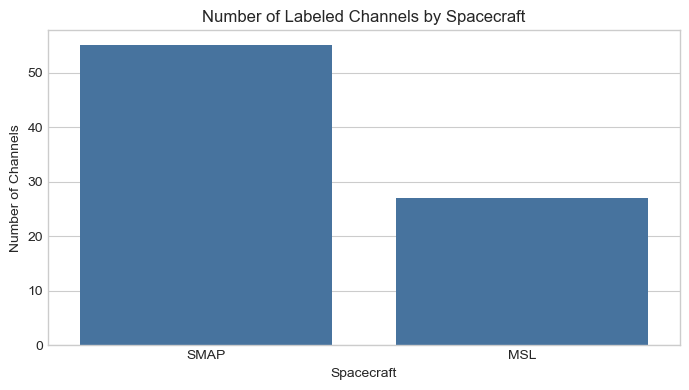

,channel_count
spacecraft,
SMAP,55
MSL,27


In [14]:
spacecraft_counts = df["spacecraft"].value_counts(dropna=False)

plt.figure(figsize=(7, 4))
sns.barplot(x=spacecraft_counts.index.astype(str), y=spacecraft_counts.values, color="#3973ac")
plt.title("Number of Labeled Channels by Spacecraft")
plt.xlabel("Spacecraft")
plt.ylabel("Number of Channels")
plt.tight_layout()
plt.show()

display(spacecraft_counts.rename("channel_count").to_frame())


## 4. Parse and validate anomaly intervals

In [15]:
def parse_sequences(seq_str):
    if isinstance(seq_str, list):
        return seq_str
    if pd.isna(seq_str):
        return []
    try:
        parsed = ast.literal_eval(str(seq_str))
        if not isinstance(parsed, (list, tuple)):
            return []
        intervals = []
        for item in parsed:
            if isinstance(item, (list, tuple)) and len(item) == 2:
                start, end = item
                if isinstance(start, (int, np.integer)) and isinstance(end, (int, np.integer)):
                    intervals.append((int(start), int(end)))
        return intervals
    except (ValueError, SyntaxError, TypeError):
        return []

df["parsed_sequences"] = df["anomaly_sequences"].apply(parse_sequences)

print("Rows:", len(df))
print("Rows with empty/unparsed anomaly intervals:", int(df["parsed_sequences"].apply(len).eq(0).sum()))
print("Rows with one or more intervals:", int(df["parsed_sequences"].apply(len).gt(0).sum()))


Rows: 82
Rows with empty/unparsed anomaly intervals: 0
Rows with one or more intervals: 82


In [16]:
# Validate interval boundaries before calculating durations.
# Current convention: [start, end), so duration = end - start.
def interval_issues(row):
    issues = []
    n = row.get("num_values")
    for start, end in row["parsed_sequences"]:
        if start < 0:
            issues.append("negative_start")
        if end <= start:
            issues.append("non_positive_interval")
        if pd.notna(n) and end > n:
            issues.append("end_exceeds_num_values")
    return sorted(set(issues))

df["interval_issues"] = df.apply(interval_issues, axis=1)
invalid_intervals = df[df["interval_issues"].apply(bool)][
    ["chan_id", "spacecraft", "num_values", "parsed_sequences", "interval_issues"]
]
print("Channels with interval boundary issues:", len(invalid_intervals))
display(invalid_intervals.head(20))


Channels with interval boundary issues: 0


,chan_id,spacecraft,num_values,parsed_sequences,interval_issues


## 5. Anomaly statistics and class imbalance

In [17]:
# These counts use the half-open interval assumption [start, end).
df["anomaly_count"] = df["parsed_sequences"].apply(len)
df["total_anomaly_points"] = df["parsed_sequences"].apply(
    lambda intervals: sum(max(0, end - start) for start, end in intervals)
)
df["total_normal_points"] = df["num_values"] - df["total_anomaly_points"]
df["anomaly_pct"] = np.where(
    df["num_values"] > 0,
    100 * df["total_anomaly_points"] / df["num_values"],
    np.nan
)

# Flag impossible totals; do not silently clip or delete records.
impossible_counts = df[
    (df["total_anomaly_points"] < 0) |
    (df["total_normal_points"] < 0) |
    (df["anomaly_pct"] > 100)
][["chan_id", "spacecraft", "num_values", "total_anomaly_points", "total_normal_points", "anomaly_pct"]]

print("Channels:", len(df))
print("Channels with at least one labeled anomaly interval:", int((df["anomaly_count"] > 0).sum()))
print("Channels with impossible derived counts:", len(impossible_counts))
display(impossible_counts.head(20))


Channels: 82
Channels with at least one labeled anomaly interval: 82
Channels with impossible derived counts: 0


,chan_id,spacecraft,num_values,total_anomaly_points,total_normal_points,anomaly_pct


In [18]:
summary_cols = [
    "num_values", "anomaly_count", "total_anomaly_points",
    "total_normal_points", "anomaly_pct"
]
display(df[summary_cols].describe().T)


,count,mean,std,min,25%,50%,75%,max
num_values,82.0,6314.195122,2701.236724,1096.000000,2997.500000,7895.500000,8472.000000,8640.000000
anomaly_count,82.0,1.280488,0.572506,1.000000,1.000000,1.000000,1.000000,3.000000
total_anomaly_points,82.0,789.073171,1105.121085,10.000000,100.000000,255.500000,1135.000000,4217.000000
total_normal_points,82.0,5525.121951,2521.422655,986.000000,2954.250000,6241.000000,7819.000000,8556.000000
anomaly_pct,82.0,12.278089,14.426169,0.393082,1.396689,6.019576,16.209946,50.065876


In [19]:
total_timesteps = df["num_values"].sum()
total_anomalies = df["total_anomaly_points"].sum()
total_normals = df["total_normal_points"].sum()

print(f"Total listed timesteps across channels: {total_timesteps:,.0f}")
print(f"Derived anomaly timesteps (interval convention dependent): {total_anomalies:,.0f}")
print(f"Derived normal timesteps: {total_normals:,.0f}")
print(f"Derived anomaly share: {100 * total_anomalies / total_timesteps:.4f}%" if total_timesteps else "No timesteps available")


Total listed timesteps across channels: 517,764
Derived anomaly timesteps (interval convention dependent): 64,704
Derived normal timesteps: 453,060
Derived anomaly share: 12.4968%


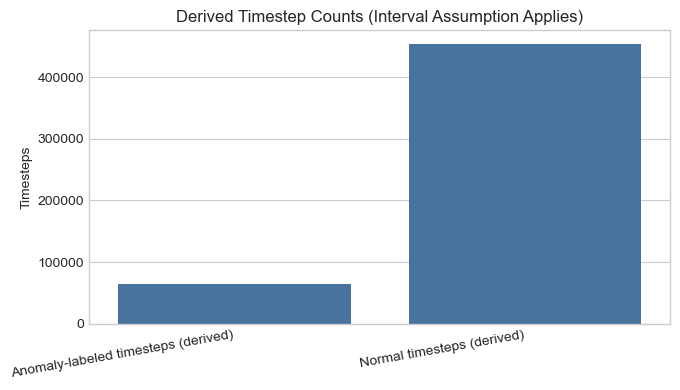

In [20]:
class_counts = pd.Series({
    "Anomaly-labeled timesteps (derived)": total_anomalies,
    "Normal timesteps (derived)": total_normals
})

plt.figure(figsize=(7, 4))
sns.barplot(x=class_counts.index, y=class_counts.values, color="#3973ac")
plt.title("Derived Timestep Counts (Interval Assumption Applies)")
plt.xlabel("")
plt.ylabel("Timesteps")
plt.xticks(rotation=10, ha="right")
plt.tight_layout()
plt.show()


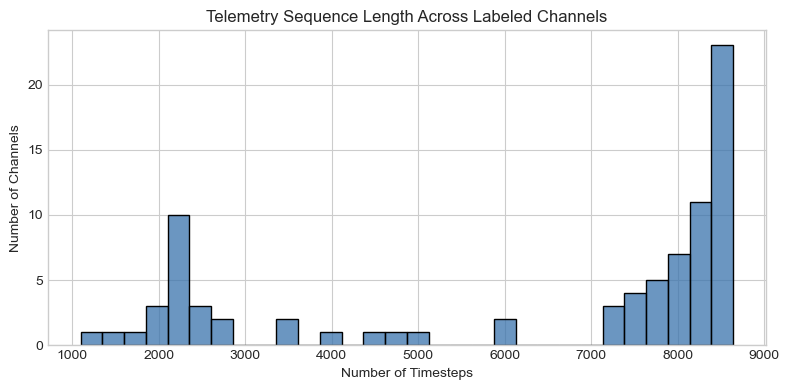

In [21]:
plt.figure(figsize=(8, 4))
sns.histplot(data=df, x="num_values", bins=30, color="#3973ac")
plt.title("Telemetry Sequence Length Across Labeled Channels")
plt.xlabel("Number of Timesteps")
plt.ylabel("Number of Channels")
plt.tight_layout()
plt.show()


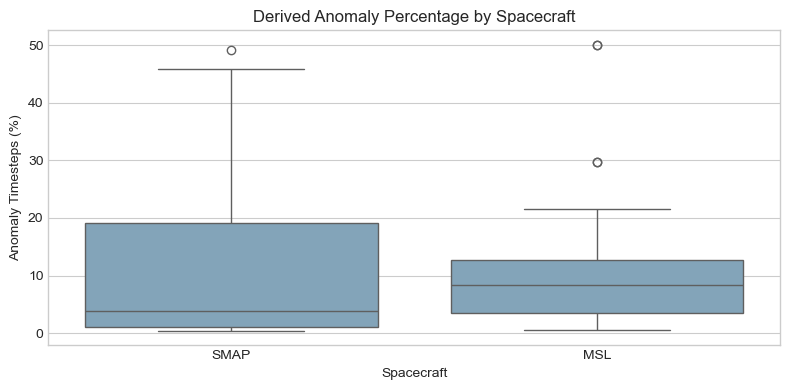

,count,median,mean,max
spacecraft,,,,
MSL,27,8.310,11.966,50.066
SMAP,55,3.858,12.431,49.063


In [22]:
plt.figure(figsize=(8, 4))
sns.boxplot(data=df, x="spacecraft", y="anomaly_pct", color="#7aa6c2")
plt.title("Derived Anomaly Percentage by Spacecraft")
plt.xlabel("Spacecraft")
plt.ylabel("Anomaly Timesteps (%)")
plt.tight_layout()
plt.show()

display(df.groupby("spacecraft")["anomaly_pct"].agg(["count", "median", "mean", "max"]).round(3))


## 6. Anomaly class metadata

,channel_class_label_count
class,
point,62
contextual,43


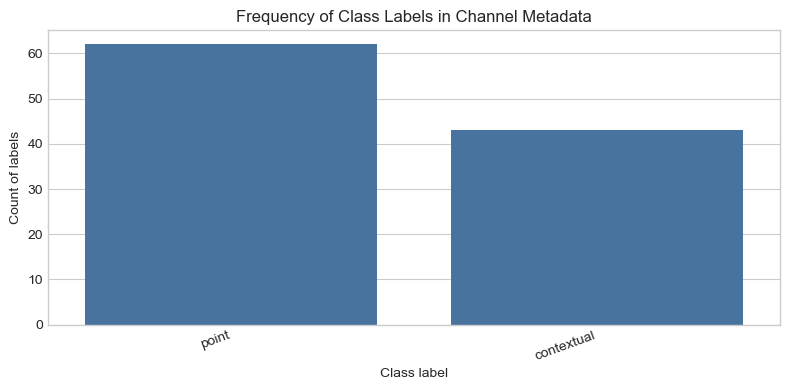

In [23]:
def parse_class_list(value):
    if pd.isna(value):
        return []
    try:
        parsed = ast.literal_eval(str(value))
        if isinstance(parsed, (list, tuple)):
            return [str(x).strip() for x in parsed if str(x).strip()]
    except (ValueError, SyntaxError, TypeError):
        pass
    text = str(value).strip().strip("[]")
    return [part.strip().strip("'\\\"") for part in text.split(",") if part.strip()]

class_counts = (
    df["class"].apply(parse_class_list)
      .explode()
      .dropna()
      .value_counts()
)
display(class_counts.rename("channel_class_label_count").to_frame())

if not class_counts.empty:
    plt.figure(figsize=(8, 4))
    sns.barplot(x=class_counts.index, y=class_counts.values, color="#3973ac")
    plt.title("Frequency of Class Labels in Channel Metadata")
    plt.xlabel("Class label")
    plt.ylabel("Count of labels")
    plt.xticks(rotation=20, ha="right")
    plt.tight_layout()
    plt.show()


## 7. Correlation between derived metadata features

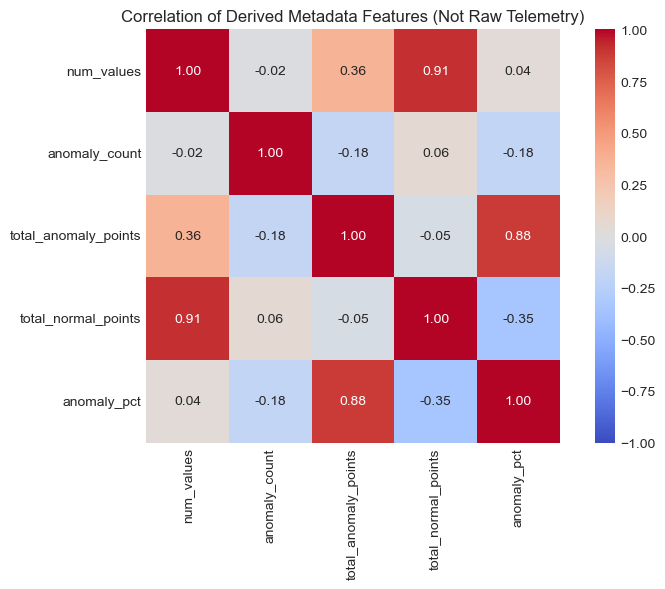

In [24]:
corr_cols = [
    "num_values", "anomaly_count", "total_anomaly_points",
    "total_normal_points", "anomaly_pct"
]
corr_matrix = df[corr_cols].corr(numeric_only=True)

plt.figure(figsize=(8, 6))
sns.heatmap(corr_matrix, annot=True, cmap="coolwarm", vmin=-1, vmax=1, fmt=".2f", square=True)
plt.title("Correlation of Derived Metadata Features (Not Raw Telemetry)")
plt.tight_layout()
plt.show()


## 8. Channels with the longest labeled anomaly intervals

In [25]:
df["max_anomaly_duration"] = df["parsed_sequences"].apply(
    lambda intervals: max((max(0, end - start) for start, end in intervals), default=0)
)

top_channels = df.sort_values("max_anomaly_duration", ascending=False)[
    ["chan_id", "spacecraft", "max_anomaly_duration", "num_values", "class"]
].head(10)

display(top_channels)


,chan_id,spacecraft,max_anomaly_duration,num_values,class
19,D-2,SMAP,4217,8595,[point]
53,A-9,SMAP,3864,8434,[contextual]
52,A-8,SMAP,3805,8375,[contextual]
20,D-3,SMAP,3275,8640,[point]
16,D-1,SMAP,3258,8509,[point]
21,D-4,SMAP,3247,8473,[point]
4,E-3,SMAP,3212,8307,[point]
37,F-2,SMAP,2956,8626,[point]
5,E-4,SMAP,2811,8354,[point]
41,D-12,SMAP,2739,7918,[point]


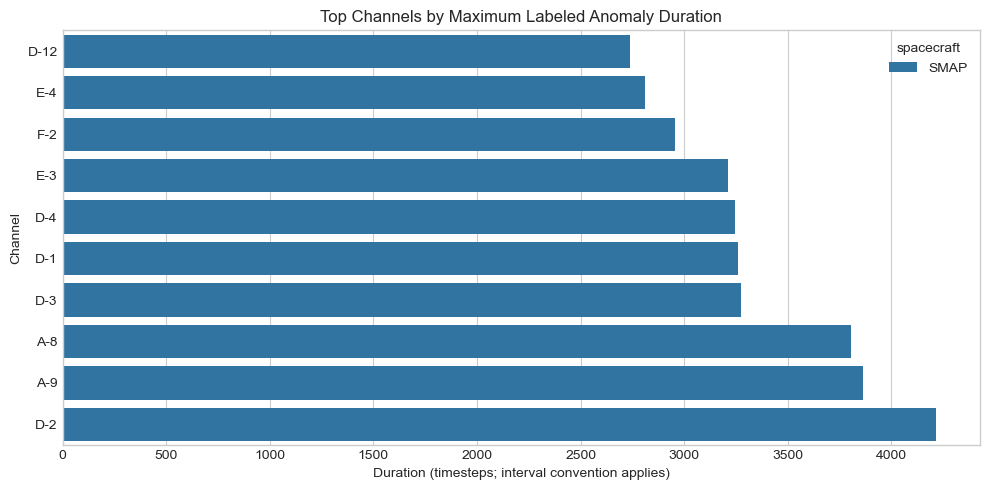

In [26]:
plt.figure(figsize=(10, 5))
plot_df = top_channels.sort_values("max_anomaly_duration", ascending=True)
sns.barplot(data=plot_df, x="max_anomaly_duration", y="chan_id", hue="spacecraft", dodge=False)
plt.title("Top Channels by Maximum Labeled Anomaly Duration")
plt.xlabel("Duration (timesteps; interval convention applies)")
plt.ylabel("Channel")
plt.tight_layout()
plt.show()


## 9. Real NASA telemetry visualization (if raw files are available)

This section searches for the actual `test/<channel>.npy` file. It does not create a simulated signal. The highlighted intervals are taken from `labeled_anomalies.csv`; confirm the dataset's interval indexing convention before interpreting the boundaries.


In [27]:
from pathlib import Path

CHANNEL_TO_PLOT = "T-1"
DATA_ROOT = Path(".")  # Set this to the folder containing the NASA dataset if needed.

channel_rows = df[df["chan_id"].astype(str) == CHANNEL_TO_PLOT]
npy_candidates = list(DATA_ROOT.rglob(f"{CHANNEL_TO_PLOT}.npy"))
test_candidates = [
    p for p in npy_candidates
    if "test" in [part.lower() for part in p.parts]
]

if channel_rows.empty:
    print(f"Channel {CHANNEL_TO_PLOT} is not present in labeled_anomalies.csv.")
elif not test_candidates:
    print(
        f"Real telemetry file for {CHANNEL_TO_PLOT} was not found under {DATA_ROOT.resolve()}. "
        "No plot was generated. Place the NASA dataset files in this folder or update DATA_ROOT."
    )
else:
    telemetry_path = test_candidates[0]
    telemetry = np.load(telemetry_path, allow_pickle=False)

    if telemetry.ndim == 1:
        telemetry = telemetry.reshape(-1, 1)
    elif telemetry.ndim != 2:
        raise ValueError(f"Unexpected telemetry shape: {telemetry.shape}")

    # If the channel occurs more than once in metadata, inspect all rows rather than silently choosing one.
    matching_rows = channel_rows[["chan_id", "spacecraft", "anomaly_sequences", "num_values"]]
    display(matching_rows)

    # Plot labels from the first matching metadata row; verify duplicates above if there is more than one.
    row = channel_rows.iloc[0]
    intervals = row["parsed_sequences"]
    signal = telemetry[:, 0]
    timesteps = np.arange(len(signal))

    plt.figure(figsize=(15, 5))
    plt.plot(timesteps, signal, linewidth=0.8, color="#24445c", label="Raw NASA telemetry (feature 0)")
    for i, (start, end) in enumerate(intervals):
        start = max(0, int(start))
        end = min(len(signal), int(end))
        if start < end:
            plt.axvspan(start, end, color="red", alpha=0.22,
                        label="Labeled anomaly interval" if i == 0 else None)

    plt.title(f"NASA {row['spacecraft']} Channel {CHANNEL_TO_PLOT}: Raw Telemetry and Labels")
    plt.xlabel("Timestep")
    plt.ylabel("Telemetry value")
    plt.legend()
    plt.tight_layout()
    plt.show()

    print("Telemetry file:", telemetry_path)
    print("Telemetry shape:", telemetry.shape)
    print("Metadata num_values:", row["num_values"])
    print("Raw telemetry timesteps:", len(telemetry))
    if len(telemetry) != row["num_values"]:
        print("WARNING: telemetry length and metadata num_values differ; verify channel/file alignment.")


Real telemetry file for T-1 was not found under C:\Users\samah\OneDrive\Desktop\Creativa\final_project. No plot was generated. Place the NASA dataset files in this folder or update DATA_ROOT.


## 10. EDA conclusions and handoff

Before modeling:
1. Confirm anomaly interval indexing (`[start, end)` versus inclusive end) from the dataset source.
2. Investigate duplicate `chan_id` records (for example, repeated IDs) without deleting them automatically.
3. Confirm the raw `.npy` files match each channel and label row.
4. Perform feature-level EDA on actual telemetry variables after loading raw arrays.
5. Split by time/channel and account for overlapping windows to prevent data leakage.

**Do not use synthetic plots as evidence about NASA telemetry.**